# Lab 10-04 · Small-Signal Models

Companion to [chapter 10-04](../../chapters/10-04-small-signal-models.md). Predict first; the `assert` lines check against the answer keys.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
VT = 1.380649e-23 * 300 / 1.602176634e-19
N = 4096
theta = 2 * np.pi * np.arange(N) / N

def harmonics(y):
    """Amplitudes of the DC term and harmonics 1, 2, 3 of one sampled period."""
    c = np.fft.rfft(y) / N
    return abs(c[0]), 2 * abs(c[1]), 2 * abs(c[2]), 2 * abs(c[3])

## Part 1 · Harmonics against amplitude

*Predict first:* at 20 mV, is the BJT's exact HD2 above or below $\hat v/4V_T$?

BJT HD2 at 20 mV: exact 18.876%, formula 19.341%;  HD3 at 10 mV: 0.6177%


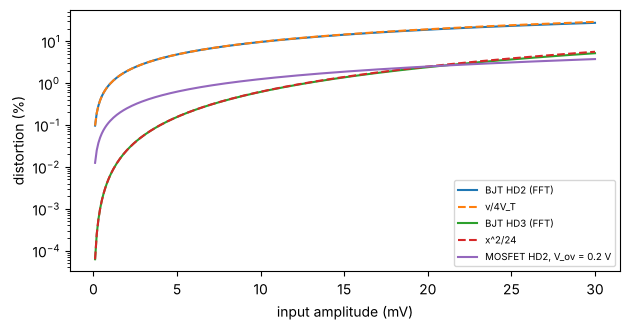

In [2]:
amps = np.linspace(0.1e-3, 30e-3, 300)
hd2_b, hd3_b, hd2_m, hd3_m = [], [], [], []
vov = 0.2
for a in amps:
    _, f1, f2, f3 = harmonics(np.exp(a / VT * np.cos(theta)))
    hd2_b.append(f2 / f1); hd3_b.append(f3 / f1)
    _, f1, f2, f3 = harmonics((vov + a * np.cos(theta)) ** 2)
    hd2_m.append(f2 / f1); hd3_m.append(f3 / f1)
hd2_b, hd3_b, hd2_m, hd3_m = map(np.array, (hd2_b, hd3_b, hd2_m, hd3_m))
assert np.allclose(hd2_m, amps / (4 * vov), rtol=1e-9) and hd3_m.max() < 1e-12   # square law: exact, no HD3

def bjt_hd(a):
    _, f1, f2, f3 = harmonics(np.exp(a / VT * np.cos(theta)))
    return f2 / f1 * 100, f3 / f1 * 100
h20, _ = bjt_hd(20e-3); _, h3_10 = bjt_hd(10e-3)
print(f"BJT HD2 at 20 mV: exact {h20:.3f}%, formula {20e-3/(4*VT)*100:.3f}%;  HD3 at 10 mV: {h3_10:.4f}%")
assert abs(h20 - 18.88) < 5e-3 and abs(20e-3 / (4 * VT) * 100 - 19.34) < 5e-3 and abs(h3_10 - 0.618) < 5e-4
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.semilogy(amps * 1e3, hd2_b * 100, label="BJT HD2 (FFT)"); ax.semilogy(amps * 1e3, amps / (4 * VT) * 100, "--", label="v/4V_T")
ax.semilogy(amps * 1e3, hd3_b * 100, label="BJT HD3 (FFT)"); ax.semilogy(amps * 1e3, (amps / VT) ** 2 / 24 * 100, "--", label="x^2/24")
ax.semilogy(amps * 1e3, hd2_m * 100, label="MOSFET HD2, V_ov = 0.2 V")
ax.set_xlabel("input amplitude (mV)"); ax.set_ylabel("distortion (%)"); ax.legend(fontsize=7); fig.tight_layout(); plt.show()

## Part 2 · The common-emitter output (guided exercise)

Example 10-04.1's stage: $I_C$ = 1 mA, $R_C$ = 5 kΩ, 10 mV peak at the base. *Predict first:* how far does the output fall, and how far does it rise?

negative peak -2.3614 V, positive peak 1.6039 V, small-signal +/-1.9341 V
average I_C rises 3.776%, average output shifts -0.1888 V


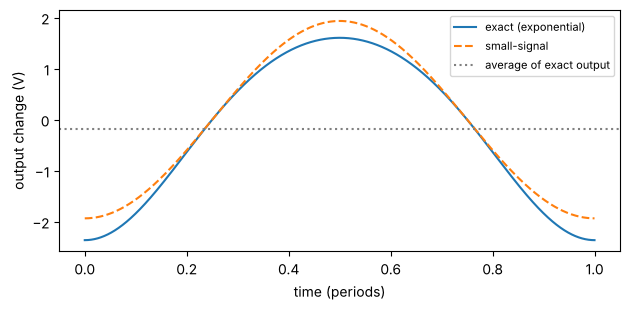

In [3]:
a = 10e-3; x = a / VT
dv_exact = -5e3 * 1e-3 * (np.exp(x * np.cos(theta)) - 1)
dv_lin = -5e3 * 1e-3 * x * np.cos(theta)
dc, *_ = harmonics(np.exp(x * np.cos(theta)))
print(f"negative peak {dv_exact.min():.4f} V, positive peak {dv_exact.max():.4f} V, small-signal +/-{abs(dv_lin).max():.4f} V")
print(f"average I_C rises {(dc - 1)*100:.3f}%, average output shifts {dv_exact.mean():.4f} V")
assert abs(dv_exact.min() + 2.361) < 5e-4 and abs(dv_exact.max() - 1.604) < 5e-4 and abs(abs(dv_lin).max() - 1.934) < 5e-4
assert abs((dc - 1) * 100 - 3.78) < 5e-3 and abs(dv_exact.mean() + 0.189) < 5e-4
plt.figure(figsize=(6.4, 3.2))
t = theta / (2 * np.pi)
plt.plot(t, dv_exact, label="exact (exponential)"); plt.plot(t, dv_lin, "--", label="small-signal")
plt.axhline(dv_exact.mean(), color="0.5", ls=":", label="average of exact output")
plt.xlabel("time (periods)"); plt.ylabel("output change (V)"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## Part 3 · $g_m/I_D$ across inversion

The EKV interpolation with $n$ = 1.3. *Predict first:* $g_m/I_D$ at threshold.

g_m/I_D at threshold 21.464/V (72.1% of 1/nV_T); at +0.2 V 9.358/V; at -0.2 V 29.027/V


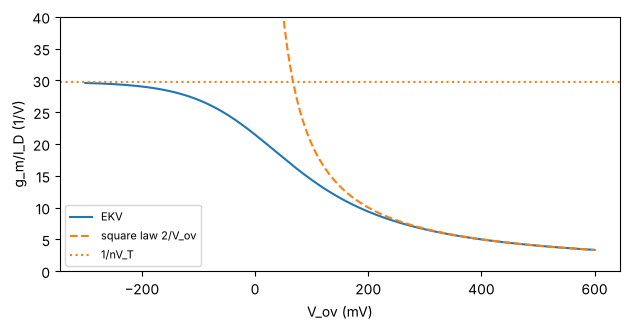

In [4]:
n = 1.3
def ekv(vov):
    return np.log1p(np.exp(vov / (2 * n * VT))) ** 2
def gm_over_id(vov, h=1e-6):
    return (math.log(ekv(vov + h)) - math.log(ekv(vov - h))) / (2 * h)
v = np.linspace(-0.3, 0.6, 400)
g = np.array([gm_over_id(x) for x in v])
g0, g02, gm02 = gm_over_id(0.0), gm_over_id(0.2), gm_over_id(-0.2)
print(f"g_m/I_D at threshold {g0:.3f}/V ({g0*n*VT*100:.1f}% of 1/nV_T); at +0.2 V {g02:.3f}/V; at -0.2 V {gm02:.3f}/V")
assert abs(g0 - 21.46) < 5e-3 and abs(g02 - 9.36) < 5e-3 and abs(gm02 - 29.03) < 5e-3
assert abs(g0 - 1 / (2 * math.log(2) * n * VT)) < 1e-6        # the closed form at threshold
plt.figure(figsize=(6.4, 3.4))
plt.plot(v * 1e3, g, label="EKV")
vp = v[v > 0.03]; plt.plot(vp * 1e3, 2 / vp, "--", label="square law 2/V_ov")
plt.axhline(1 / (n * VT), ls=":", color="C1", label="1/nV_T")
plt.ylim(0, 40); plt.xlabel("V_ov (mV)"); plt.ylabel("g_m/I_D (1/V)"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## Part 4 · Two models, one circuit

Random degenerated common-emitter stages: β from 50 to 400, $I_C$ from 10 µA to 10 mA, $R_E$ from 0 to 1 kΩ, $R_C$ from 1 to 20 kΩ. The hybrid-π model is solved as nodal equations at the emitter; the T model in one line.

In [5]:
rng = np.random.default_rng(1004)
worst = 0.0
for _ in range(200):
    beta = rng.uniform(50, 400); ic = 10 ** rng.uniform(-5, -2); re = rng.uniform(0, 1e3); rc = rng.uniform(1e3, 20e3)
    gm = ic / VT; rpi = beta / gm; alpha = beta / (beta + 1); r_e = alpha / gm
    # hybrid-pi: unknown emitter voltage ve with vb = 1; KCL at the emitter: (1 - ve)/rpi + gm (1 - ve) = ve/re
    if re == 0:
        ve = 0.0
    else:
        ve = (1 / rpi + gm) / (1 / rpi + gm + 1 / re)
    a_hpi = -gm * (1 - ve) * rc
    a_t = -alpha * rc / (r_e + re)
    worst = max(worst, abs(a_hpi / a_t - 1))
print(f"largest relative disagreement over 200 circuits: {worst:.2e}")
assert worst < 1e-12

largest relative disagreement over 200 circuits: 3.02e-14
